### Проверка устройства

In [1]:
import sys
sys.path.append('../src')

import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

print(f"CUDA доступна: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"Память: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")
else:
    print("Работа ведётся на CPU (это будет долго)")

CUDA доступна: True
GPU: NVIDIA GeForce RTX 3050 Laptop GPU
Память: 4.3 GB


### Загрузка и подготовка

In [2]:
from dataset import build_item_vocab, build_user_sequences
from train import train

PROC = Path('../data/processed')
train_df = pd.read_parquet(PROC / 'train.parquet')
val_df = pd.read_parquet(PROC / 'val.parquet')

item2idx, idx2item = build_item_vocab(train_df)
vocab_size = len(item2idx) + 2
print(f"Vocab size: {vocab_size}")

train_seqs = build_user_sequences(train_df, max_len=50)
val_seqs = build_user_sequences(val_df, max_len=50)
print(f"Train users: {len(train_seqs):,}, Val users: {len(val_seqs):,}")

Vocab size: 14937
Train users: 727,645, Val users: 118,727


### Небольшой тест на маленьком куске

In [3]:
# Обрезка данные для быстрой проверки
sample_users = list(train_seqs.keys())[:1000]
train_seqs_small = {u: train_seqs[u] for u in sample_users}

val_users = list(val_seqs.keys())[:200]
val_seqs_small = {u: val_seqs[u] for u in val_users}

# Обучение на 1 эпоху с маленьким батчем
history = train(
    train_sequences=train_seqs_small,
    val_sequences=val_seqs_small,
    item2idx=item2idx,
    vocab_size=vocab_size,
    batch_size=64,
    n_epochs=1,
    lr=1e-3,
    save_dir='../results/checkpoints_test',
    patience=10,
)

[transformers] Model config: bos_token_id must be `None` or an integer within the vocabulary (between 0 and 14936), got 50256. This may result in unexpected behavior.
[transformers] Model config: eos_token_id must be `None` or an integer within the vocabulary (between 0 and 14936), got 50256. This may result in unexpected behavior.


Устройство: cuda
Train examples: 632
Val examples:   116
Train batches/epoch: 9

Начинаем обучение: 1 эпох, batch=64, lr=0.001
Warmup: 0 шагов из 9

--- Эпоха 1/1 ---


[transformers] `loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


  train_loss = 9.2920
  val_loss   = 9.1968
  lr         = 0.00e+00
  время      = 3.6 сек

  Новый best val_loss: 9.1968


Обучение завершено. Лучший val_loss: 9.1968
Чекпоинты сохранены в: ..\results\checkpoints_test


### ПОЛНОЕ ОБУЧЕНИЕ!!!

In [4]:
# ЗАПУСКАТЬ ТОЛЬКО ЕСЛИ ЕСТЬ GPU ИЛИ ЕСЛИ МНОГО СВОБОДНОГО ВРЕМЕНИ

history_full = train(
    train_sequences=train_seqs,
    val_sequences=val_seqs,
    item2idx=item2idx,
    vocab_size=vocab_size,
    batch_size=256,
    n_epochs=3,
    lr=1e-3,
    save_dir='../results/checkpoints',
    patience=3,
)

Устройство: cuda


Train examples: 451,120
Val examples:   67,361
Train batches/epoch: 1,762

Начинаем обучение: 3 эпох, batch=256, lr=0.001
Warmup: 528 шагов из 5286

--- Эпоха 1/3 ---
    batch 200: loss = 7.1792
    batch 400: loss = 6.8385
    batch 600: loss = 6.7650
    batch 800: loss = 6.6968
    batch 1000: loss = 6.5323
    batch 1200: loss = 6.2745
    batch 1400: loss = 6.5136
    batch 1600: loss = 6.3910
  train_loss = 6.7839
  val_loss   = 7.2314
  lr         = 8.43e-04
  время      = 509.1 сек

  Новый best val_loss: 7.2314

--- Эпоха 2/3 ---
    batch 200: loss = 6.5261
    batch 400: loss = 6.3625
    batch 600: loss = 6.2886
    batch 800: loss = 6.4308
    batch 1000: loss = 6.3871
    batch 1200: loss = 6.2476
    batch 1400: loss = 6.2169
    batch 1600: loss = 6.3023
  train_loss = 6.3240
  val_loss   = 7.1648
  lr         = 3.02e-04
  время      = 520.4 сек

  Новый best val_loss: 7.1648

--- Эпоха 3/3 ---
    batch 200: loss = 6.2946
    batch 400: loss = 6.4859
    batch 600: lo

### Графики

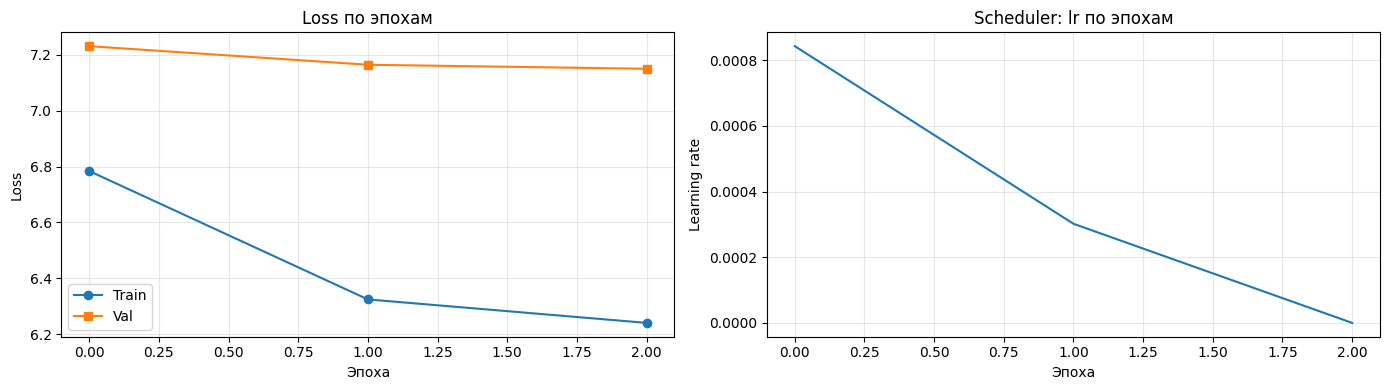

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].plot(history_full['train_loss'], marker='o', label='Train')
axes[0].plot(history_full['val_loss'], marker='s', label='Val')
axes[0].set_xlabel('Эпоха')
axes[0].set_ylabel('Loss')
axes[0].set_title('Loss по эпохам')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(history_full['lr'])
axes[1].set_xlabel('Эпоха')
axes[1].set_ylabel('Learning rate')
axes[1].set_title('Scheduler: lr по эпохам')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('../results/training_curves.png', dpi=100)
plt.show()